# Classifiers, pipelines and the confusion matrix

Which customers of a telecom company will cancel their contract? After this block you can prepare a table of numbers and text categories for a model in a leak-free `Pipeline`, build churn classifiers (a hand-made rule, k-nearest neighbours, logistic regression) and compare them with honest baselines, and judge them by the errors they make: the confusion matrix, accuracy, precision, recall, F1 and macro-F1. You can also say which of these numbers fits a given business question.

*Course material, licence CC BY 4.0. Sections marked "Adapted from" curate text and code from the INRIA scikit-learn MOOC (CC BY 4.0) and the scikit-learn example gallery (BSD-3-Clause); see [extras/README.md](extras/README.md). Data: IBM Telco customer churn sample (Apache 2.0), downloaded from IBM's GitHub repository.*

## Overview

| Section | What it covers |
|---|---|
| Classification tasks and baselines | binary and multiclass tasks, the positive class, the Telco churn data and a locked test set, the majority-class baseline and a hand-made rule, all `DummyClassifier` strategies |
| Preparing inputs: encoding and scaling | numeric and categorical columns, choosing columns by type, one-hot encoding, ordinal encoding and its order, rare and unseen categories, `StandardScaler`, `fit`, `transform` and `fit_transform`, scaling and solver iterations |
| Pipeline and ColumnTransformer | `ColumnTransformer`, `Pipeline`, what happens inside `fit` and `predict`, `make_column_transformer` and `remainder`, cross-validating the pipeline, a pipeline for gradient boosting, fitting the pipeline and never the parts |
| k-nearest neighbours and the decision boundary | how k-NN votes, decision boundaries for different *k*, choosing *k* by cross-validation, uniform and distance weights, limits of k-NN |
| Confusion matrix, accuracy, precision, recall and F1 | the four counts, accuracy, precision, recall and F1, the classification report, normalised matrices, sensitivity, specificity and balanced accuracy, `pos_label` and `zero_division`, predicted classes from probabilities |
| Macro-F1 for several classes | macro, weighted and micro averages, a toy example, macro-F1 for the churn models, a three-class contract task |
| Worked example | the baseline, the rule, k-NN and logistic regression compared by cross-validation, one look at the test set |
| Check your understanding, Exercises, Debrief | five questions, six exercises in pairs, what to compare afterwards |

## Classification tasks and baselines

A **classification** model predicts a category, the **class**, from the features of a case. With two classes (churns or stays, spam or not spam) the task is **binary**; with more (the room type of an Airbnb listing, or the tariff heading of a customs decision in Session 13) it is **multiclass**. The class we care about, usually the rarer one, is called **positive** and coded 1. Here that is "churns".

### The churn data and a locked test set

First we load the Telco data. `pd.to_numeric(..., errors="coerce")` turns the blank strings in `TotalCharges` into missing values (`NaN`), and `(telco["Churn"] == "Yes").astype(int)` codes the target as 0 or 1.

In [1]:
import numpy as np
import pandas as pd

URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
telco = pd.read_csv(URL)
telco["TotalCharges"] = pd.to_numeric(telco["TotalCharges"], errors="coerce")
y = (telco["Churn"] == "Yes").astype(int)
X = telco.drop(columns=["customerID", "Churn"])
print(X.shape, "| missing TotalCharges:", X["TotalCharges"].isna().sum())
print(y.value_counts().to_dict(), "| churn rate", round(y.mean(), 3))

(7043, 19) | missing TotalCharges: 11
{0: 5174, 1: 1869} | churn rate 0.265


Next we lock away a test set, as in Session 7. `stratify=y` keeps the churn rate the same in both parts, and `StratifiedKFold` does the same for every cross-validation fold we use later.

In [2]:
from sklearn.model_selection import StratifiedKFold, train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)
cv = StratifiedKFold(5, shuffle=True, random_state=0)
print(len(X_train), "training customers,", len(X_test), "test customers")

5282 training customers, 1761 test customers


### Baselines: the majority class and a hand-made rule

Before we train anything we write down **baselines**: cheap predictions that a model must beat to be worth its cost.

- The **majority-class baseline** predicts the most frequent class for everybody.
- A **hand-made rule** encodes what the business already knows, for example "customers on a month-to-month contract in their first year will leave".

Think of a weather forecaster in a dry city. Saying "no rain" every day is right most of the time, but nobody would call it a forecast.

**Predict before running.** About a quarter of the customers churn. What accuracy does "nobody churns" reach on the test set?

`DummyClassifier(strategy="most_frequent")` is the majority baseline with the usual `fit` / `score` interface. The rule is a Boolean expression on two columns; `accuracy_score(y_true, y_pred)` and `recall_score` compare it with the truth. Recall is the share of churners we find (the confusion-matrix section below defines it properly).

In [3]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print("nobody churns:  accuracy", round(dummy.score(X_test, y_test), 3))

rule = ((X_test["Contract"] == "Month-to-month") & (X_test["tenure"] < 12)).astype(int)
print("hand-made rule: accuracy", round(accuracy_score(y_test, rule), 3),
      "| share of churners found", round(recall_score(y_test, rule), 3))

nobody churns:  accuracy 0.735
hand-made rule: accuracy 0.756 | share of churners found 0.555


"Nobody churns" is right for almost three customers in four and finds no churner at all. The rule is only slightly more accurate but finds about half of the churners. Accuracy alone hardly separates the two; the confusion-matrix section introduces metrics that do.

> **Note.** On imbalanced data a high accuracy can simply mean "predicts the majority class". Always report the majority baseline next to your model.

### The other dummy strategies

`DummyClassifier` has more strategies than "most frequent", and each answers a different question:

- `"most_frequent"` and `"prior"` always predict the majority class; `"prior"` also returns the class shares (0.735, 0.265) as probabilities, which gives a proper baseline for probability metrics in Block 2;
- `"stratified"` draws random labels with the class shares of the training data: a coin that is biased like the data;
- `"uniform"` draws each class with equal probability;
- `"constant"` always predicts a value you choose, for example `constant=1` for "everybody churns", the policy "send an offer to everyone".

Next we compare them on the test set by accuracy and recall. `DummyClassifier(strategy=..., random_state=0)` makes the random strategies reproducible.

In [4]:
for strategy, kw in [("most_frequent", {}), ("stratified", {}), ("uniform", {}), ("constant", {"constant": 1})]:
    d = DummyClassifier(strategy=strategy, random_state=0, **kw).fit(X_train, y_train)
    p = d.predict(X_test)
    print(f"{strategy:14s} accuracy {accuracy_score(y_test, p):.3f}   recall {recall_score(y_test, p):.3f}")

most_frequent  accuracy 0.735   recall 0.000
stratified     accuracy 0.591   recall 0.248
uniform        accuracy 0.516   recall 0.548
constant       accuracy 0.265   recall 1.000


"Everybody churns" has recall 1 and the worst accuracy; random guessing finds about as many churners as its guessing rate. A useful model must beat all of these on the metric that matters for the decision, not only on accuracy.

## Preparing inputs: encoding and scaling

Most models compute with numbers. The Telco table has 4 numeric columns and 15 text columns such as `Contract` ("Month-to-month", "One year", "Two year") or `PaymentMethod`. Numeric variables are quantities (tenure in months, charges in dollars); **categorical** variables take one value from a finite list of labels. The subsections below turn them into model inputs: one-hot or ordinal encoding for the categories, scaling for the numbers.

Encoders and scalers *learn* something (the categories, the mean, the standard deviation), so they have a `fit` step, and that step must only see training data.

### Choosing columns by their type

*Adapted from [Encoding of categorical variables](https://inria.github.io/scikit-learn-mooc/python_scripts/03_categorical_pipeline.html) and [Using numerical and categorical variables together](https://inria.github.io/scikit-learn-mooc/python_scripts/03_categorical_pipeline_column_transformer.html) (INRIA scikit-learn MOOC, CC BY 4.0).*

How do we find the categorical columns without typing 15 names? Part of the answer is the column's data type: text columns have the pandas type `object`. scikit-learn's `make_column_selector(dtype_include=object)` returns a function that, applied to a table, lists the matching column names.

In [5]:
from sklearn.compose import make_column_selector as selector

categorical_by_type = selector(dtype_include=object)(X_train)
numeric_by_type = selector(dtype_exclude=object)(X_train)
print(len(categorical_by_type), "object columns, e.g.", categorical_by_type[:4])
print("numeric:", numeric_by_type)

15 object columns, e.g. ['gender', 'Partner', 'Dependents', 'PhoneService']
numeric: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


The selector found `SeniorCitizen` as numeric: it is stored as 0/1, although it is really a yes/no category. For 0/1 columns this does no harm, but the lesson is general: an `object` column may also hold badly formatted numbers or dates (as `TotalCharges` did before we converted it), and a number may encode a category (a postcode, a product code). Look at the columns before trusting a selector. `X.nunique()` shows how many distinct values each column has.

In [6]:
print(X_train.nunique().sort_values().head(8).to_dict())

{'gender': 2, 'SeniorCitizen': 2, 'Partner': 2, 'Dependents': 2, 'PaperlessBilling': 2, 'PhoneService': 2, 'Contract': 3, 'StreamingMovies': 3}


### One-hot encoding

**One-hot encoding** turns a column with *m* categories into *m* columns of 0 and 1, one per category. It invents no order and suits **nominal** categories such as the payment method.

`OneHotEncoder(sparse_output=False)` returns a normal array; `get_feature_names_out()` names the new columns. `handle_unknown="ignore"` encodes a category never seen in training ("Ten year" below) as all zeros instead of raising an error.

In [7]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

onehot = OneHotEncoder(sparse_output=False, handle_unknown="ignore").fit(X_train[["Contract"]])
print(onehot.get_feature_names_out())
print(onehot.transform(pd.DataFrame({"Contract": ["Two year", "Month-to-month", "Ten year"]})))

['Contract_Month-to-month' 'Contract_One year' 'Contract_Two year']
[[0. 0. 1.]
 [1. 0. 0.]
 [0. 0. 0.]]


### Ordinal encoding

**Ordinal encoding** maps categories to 0, 1, 2, ... in an order you give. It suits **ordinal** categories with a real order, such as contract length or a satisfaction score from 1 to 5. Used on nominal categories, it invents distances that do not exist ("credit card is twice bank transfer").

**Predict before running.** `OrdinalEncoder(categories=[order])` uses the order you pass. What does it return for "Two year" and for "Month-to-month"?

In [8]:
order = [["Month-to-month", "One year", "Two year"]]
ordinal = OrdinalEncoder(categories=order).fit(X_train[["Contract"]])
print(ordinal.transform(pd.DataFrame({"Contract": ["Two year", "Month-to-month"]})).ravel())

[2. 0.]


### The order of an ordinal encoding

*Adapted from [Encoding of categorical variables](https://inria.github.io/scikit-learn-mooc/python_scripts/03_categorical_pipeline.html) (INRIA scikit-learn MOOC, CC BY 4.0).*

By default `OrdinalEncoder` sorts the categories alphabetically. That order is arbitrary and often meaningless: clothing sizes "S", "M", "L", "XL" would become L = 0, M = 1, S = 2, XL = 3. For contracts, the alphabetical order happens to be right, but for `PaymentMethod` any order is invented. The fitted attribute `categories_` shows which number each category received.

In [9]:
auto = OrdinalEncoder().fit(X_train[["PaymentMethod"]])
print(list(enumerate(auto.categories_[0])))
sizes = OrdinalEncoder().fit(pd.DataFrame({"size": ["S", "M", "L", "XL"]}))
print(list(enumerate(sizes.categories_[0])))

[(0, 'Bank transfer (automatic)'), (1, 'Credit card (automatic)'), (2, 'Electronic check'), (3, 'Mailed check')]
[(0, 'L'), (1, 'M'), (2, 'S'), (3, 'XL')]


A linear model reads these numbers as quantities: it would assume that "Mailed check" (3) is three times as far from "Bank transfer" (0) as "Credit card" (1). Tree-based models (Session 10) only split the numbers into groups, so for them an arbitrary order does little harm. The usual rule is therefore: **one-hot encoding for linear and distance-based models, ordinal encoding for tree-based models**, or for categories with a true order.

One-hot encoding of all 15 text columns of the Telco table gives the following number of columns:

In [10]:
all_onehot = OneHotEncoder(sparse_output=False).fit(X_train[categorical_by_type])
print(len(categorical_by_type), "categorical columns ->", len(all_onehot.get_feature_names_out()), "0/1 columns")

15 categorical columns -> 41 0/1 columns


### Rare and unseen categories

*Adapted from [Encoding of categorical variables](https://inria.github.io/scikit-learn-mooc/python_scripts/03_categorical_pipeline.html) (INRIA scikit-learn MOOC, CC BY 4.0).*

A category that occurs only a handful of times can end up entirely in a validation fold or the test set. The encoder has never seen it, and by default it raises an error. scikit-learn offers three ways out:

- list all possible categories yourself with `categories=` instead of learning them in `fit`;
- `OneHotEncoder(handle_unknown="ignore")`: an unknown category becomes all zeros;
- `OneHotEncoder(min_frequency=k)`: categories seen fewer than *k* times in training are merged into one "infrequent" column; with `handle_unknown="infrequent_if_exist"` unknown categories go to that column too.

`OrdinalEncoder` has its own version: `handle_unknown="use_encoded_value", unknown_value=-1` turns unknown categories into −1. Next we try the default and the safe setting on a new payment method. The `try/except` block catches the error so the notebook keeps running.

In [11]:
new = pd.DataFrame({"PaymentMethod": ["Bitcoin"]})
try:
    OneHotEncoder().fit(X_train[["PaymentMethod"]]).transform(new)
except ValueError as err:
    print("default encoder:", str(err)[:80], "...")
print("ignore:", OneHotEncoder(handle_unknown="ignore").fit(X_train[["PaymentMethod"]]).transform(new).toarray())
safe_ord = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1).fit(X_train[["PaymentMethod"]])
print("ordinal:", safe_ord.transform(new))

default encoder: Found unknown categories ['Bitcoin'] in column 0 during transform ...
ignore: [[0. 0. 0. 0.]]
ordinal: [[-1.]]


### Scaling with `StandardScaler`

**Scaling** puts the numeric columns on comparable scales. A distance between customers adds up differences in every column. Tenure runs from 0 to 72 months, total charges into the thousands of dollars, so without scaling total charges decide everything. **Standardisation** (`StandardScaler`) subtracts the training mean and divides by the training standard deviation, so every numeric column is measured in "standard deviations from the average customer".

`StandardScaler` stores the training mean in `mean_` and the standard deviation in `scale_`. A new customer with 0 or 72 months of tenure is then expressed in standard deviations.

In [12]:
scaler = StandardScaler().fit(X_train[["tenure"]])
print("mean", scaler.mean_.round(1), "| SD", scaler.scale_.round(1))
print(scaler.transform(pd.DataFrame({"tenure": [0, 72]})).ravel().round(2))

mean [32.1] | SD [24.5]
[-1.31  1.63]


### What `fit`, `transform` and `fit_transform` do

*Adapted from [Preprocessing for numerical features](https://inria.github.io/scikit-learn-mooc/python_scripts/02_numerical_pipeline_scaling.html) (INRIA scikit-learn MOOC, CC BY 4.0); diagrams from the MOOC.*

A **transformer** is an estimator with a `transform` method. Its `fit` takes only the data (no target) and learns the **model states**, here one mean and one standard deviation per column. scikit-learn's convention: every attribute learned from data ends with an underscore (`mean_`, `scale_`).

![Transformer fit diagram](../figures/api_diagram-transformer.fit.svg)

`transform` applies a fixed **transformation function** to new data, using the stored states. It is the transformer's counterpart of a model's `predict`, but its output is a new version of the data rather than predictions.

![Transformer transform diagram](../figures/api_diagram-transformer.transform.svg)

`fit_transform` is a shorthand for `fit` followed by `transform` on the same data. Use it on training data only; on test data call `transform`.

![Transformer fit_transform diagram](../figures/api_diagram-transformer.fit_transform.svg)

Since scikit-learn 1.2, `set_output(transform="pandas")` returns a DataFrame with column names, which makes checking easier. After standardisation every column has mean 0 and standard deviation 1 on the training data:

In [13]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
scaled = StandardScaler().set_output(transform="pandas").fit_transform(X_train[num_cols])
print(X_train[num_cols].describe().loc[["mean", "std", "min", "max"]].round(1))
print(scaled.describe().loc[["mean", "std", "min", "max"]].round(2))

      tenure  MonthlyCharges  TotalCharges
mean    32.1            64.3        2256.0
std     24.5            30.1        2252.1
min      0.0            18.2          18.8
max     72.0           118.8        8672.4
      tenure  MonthlyCharges  TotalCharges
mean   -0.00            0.00          0.00
std     1.00            1.00          1.00
min    -1.31           -1.53         -0.99
max     1.63            1.81          2.85


Scaling shifts and stretches the axes but does not change the shape of the data. The scatter plots below show 300 training customers before and after scaling: the same cloud, new units. `plt.subplots(1, 2)` puts two plots side by side.

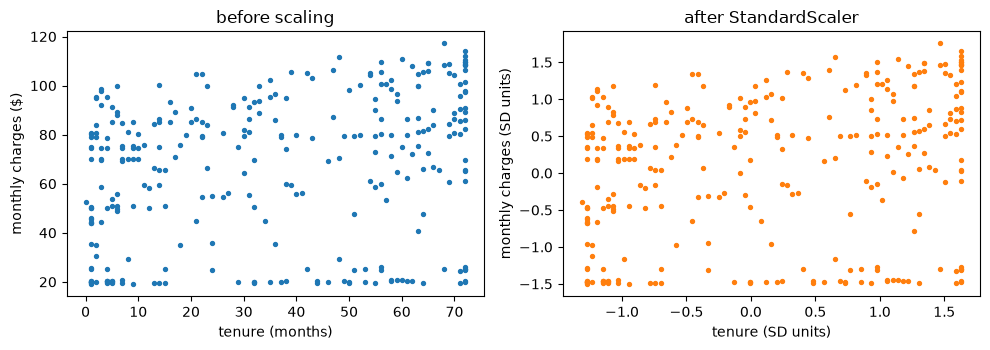

In [14]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].scatter(X_train["tenure"][:300], X_train["MonthlyCharges"][:300], s=8)
axes[0].set(xlabel="tenure (months)", ylabel="monthly charges ($)", title="before scaling")
axes[1].scatter(scaled["tenure"][:300], scaled["MonthlyCharges"][:300], s=8, color="tab:orange")
axes[1].set(xlabel="tenure (SD units)", ylabel="monthly charges (SD units)", title="after StandardScaler")
plt.tight_layout()
plt.show()

### Why scaling also speeds up the solver

*Adapted from [Preprocessing for numerical features](https://inria.github.io/scikit-learn-mooc/python_scripts/02_numerical_pipeline_scaling.html) (INRIA scikit-learn MOOC, CC BY 4.0).*

There are two reasons to scale. Distance-based models such as k-NN need it so that every feature contributes to the distance on a comparable scale. And models fitted by a numerical solver, such as logistic regression, find their coefficients in fewer steps (**iterations**) when the features have similar scales. Next we fit a logistic regression on the three numeric columns with and without scaling and read the number of iterations from `n_iter_`. `SimpleImputer` fills the 11 missing `TotalCharges` (the pipeline section explains it). `warnings.catch_warnings()` silences the convergence warning of the unscaled fit so we can print it ourselves.

In [15]:
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

for name, steps in [("unscaled", [SimpleImputer()]), ("scaled", [SimpleImputer(), StandardScaler()])]:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        m = make_pipeline(*steps, LogisticRegression(max_iter=100)).fit(X_train[num_cols], y_train)
    print(f"{name:9s} iterations {m[-1].n_iter_[0]:3d}   test accuracy {m.score(X_test[num_cols], y_test):.3f}")

unscaled  iterations  54   test accuracy 0.783
scaled    iterations  11   test accuracy 0.783


Scaling cut the number of iterations by a factor of about five; the accuracy is the same because both fits converged. If the number of iterations reaches `max_iter` (100 by default), the solver has stopped before converging. Before raising `max_iter`, make sure the data are well scaled. One-hot columns are already on a common 0/1 scale and do not need scaling.

> 📖 **Read more:** [extras/01-categorical-encoding.ipynb](extras/01-categorical-encoding.ipynb) and [extras/02-scaling-in-pipelines.ipynb](extras/02-scaling-in-pipelines.ipynb) (INRIA scikit-learn MOOC): the same ideas on the adult census data, the source of much of this section.

## Pipeline and ColumnTransformer

Preparing every column by hand and remembering to fit only on training data is error-prone. scikit-learn offers two building blocks:

- A **`ColumnTransformer`** sends different columns to different preparation steps and glues the results together: impute and scale the numeric columns, one-hot encode the text columns.
- A **`Pipeline`** chains the preparation and the model into one estimator. `fit` fits every step on the data it receives; `predict` applies the stored steps to new data.

The pipeline is like a recipe card that travels with the dish: whoever cooks it later (the test set, next month's customers, the web service of Session 16) follows exactly the same steps. And because it is one estimator, `cross_val_score` and `GridSearchCV` refit the whole preparation inside every fold, so no information leaks from validation folds (Session 7).

The whole preparation and the model of this block, as one pipeline:

```mermaid
flowchart LR
    R["Raw table:<br/>numbers + categories"] --> CT["ColumnTransformer"]
    CT --> N["numeric columns:<br/>impute, scale"]
    CT --> C["categorical columns:<br/>one-hot encode"]
    N --> M["model:<br/>k-NN or logistic regression"]
    C --> M
    M --> P["predicted class"]
    P --> E["confusion matrix:<br/>precision, recall, F1"]
```

### `ColumnTransformer`: a different preparation for each group of columns

Next we build the preparation. Each entry of `ColumnTransformer([...])` is a triple `(name, transformer, columns)`. `make_pipeline(a, b)` chains steps and names them automatically. `SimpleImputer(strategy="median")` fills the 11 missing `TotalCharges` with the training median.

In [16]:
from sklearn.compose import ColumnTransformer

numeric = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]
categorical = [c for c in X.columns if c not in numeric]
pre = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
])
print(len(numeric), "numeric and", len(categorical), "categorical columns")

4 numeric and 15 categorical columns


### `Pipeline`: preparation and model as one estimator

Now the model goes at the end. `logreg[:-1]` is the pipeline without its last step, so `logreg[:-1].transform(X_test)` shows what the model actually receives. `predict_proba(X)[:, 1]` returns the predicted churn probabilities.

In [17]:
logreg = make_pipeline(pre, LogisticRegression(max_iter=1000)).fit(X_train, y_train)
print("input to the model:", logreg[:-1].transform(X_test).shape)
print("test accuracy:", round(logreg.score(X_test, y_test), 3))
print("first churn probabilities:", logreg.predict_proba(X_test)[:3, 1].round(2))

input to the model: (1761, 45)
test accuracy: 0.792
first churn probabilities: [0.48 0.12 0.  ]


### What happens inside `fit` and `predict`

*Adapted from [Preprocessing for numerical features](https://inria.github.io/scikit-learn-mooc/python_scripts/02_numerical_pipeline_scaling.html) and [Using numerical and categorical variables together](https://inria.github.io/scikit-learn-mooc/python_scripts/03_categorical_pipeline_column_transformer.html) (INRIA scikit-learn MOOC, CC BY 4.0); diagrams from the MOOC.*

When we call `pipeline.fit(X, y)`, every transformer calls `fit_transform`: it learns its states and passes the transformed data on. The last step, the predictor, is fitted on the fully transformed data.

![Pipeline fit diagram](../figures/api_diagram-pipeline.fit.svg)

When we call `pipeline.predict(X_new)`, every transformer only calls `transform` with the stored states (no new learning), and the predictor calls `predict`.

![Pipeline predict diagram](../figures/api_diagram-pipeline.predict.svg)

A `ColumnTransformer` itself does three things: it **splits** the columns into the listed subsets, **transforms** each subset with its own transformer (`fit_transform` during fitting, `transform` afterwards), and **concatenates** the results into one table.

![ColumnTransformer diagram](../figures/api_diagram-columntransformer.svg)

`named_steps` lists the steps of a pipeline by name, and `named_transformers_` the fitted parts of a column transformer:

In [18]:
print(list(logreg.named_steps))
fitted_pre = logreg.named_steps["columntransformer"]
print(fitted_pre.named_transformers_["num"][-1].mean_.round(2))     # learned on X_train only
print(fitted_pre.get_feature_names_out()[:6])

['columntransformer', 'logisticregression']
[3.21300e+01 6.43400e+01 2.25452e+03 1.70000e-01]
['num__tenure' 'num__MonthlyCharges' 'num__TotalCharges'
 'num__SeniorCitizen' 'cat__gender_Female' 'cat__gender_Male']


### `make_column_transformer`, selectors and `remainder`

*Adapted from [Using numerical and categorical variables together](https://inria.github.io/scikit-learn-mooc/python_scripts/03_categorical_pipeline_column_transformer.html) (INRIA scikit-learn MOOC, CC BY 4.0).*

`make_column_transformer` is the shorthand that names the parts automatically, and it accepts a selector instead of a list of names. `remainder` decides what happens to columns that no transformer claims: `"drop"` (the default), `"passthrough"`, or a transformer such as `StandardScaler()`.

In [19]:
from sklearn.compose import make_column_transformer

pre_short = make_column_transformer(
    (OneHotEncoder(handle_unknown="ignore"), selector(dtype_include=object)),
    remainder=make_pipeline(SimpleImputer(strategy="median"), StandardScaler()),
)
print(pre_short.fit_transform(X_train).shape)

(5282, 45)


### Cross-validating the whole pipeline

*Adapted from [Using numerical and categorical variables together](https://inria.github.io/scikit-learn-mooc/python_scripts/03_categorical_pipeline_column_transformer.html) (INRIA scikit-learn MOOC, CC BY 4.0).*

A single train/test split gives one number. `cross_validate` refits the whole pipeline (imputer, scaler, encoder, model) on each training fold and reports the score on each validation fold, together with the time needed to fit and to score. The spread over the folds shows how uncertain the estimate is.

In [20]:
from sklearn.model_selection import cross_validate

cv_res = pd.DataFrame(cross_validate(logreg, X_train, y_train, cv=cv))
print(cv_res.round(3))
print(f"accuracy {cv_res['test_score'].mean():.3f} +/- {cv_res['test_score'].std():.3f}")

   fit_time  score_time  test_score
0     0.022       0.006       0.793
1     0.021       0.007       0.784
2     0.023       0.009       0.822
3     0.029       0.012       0.842
4     0.025       0.007       0.791
accuracy 0.806 +/- 0.025


### A pipeline for a tree-based model

*Adapted from [Using numerical and categorical variables together](https://inria.github.io/scikit-learn-mooc/python_scripts/03_categorical_pipeline_column_transformer.html) (INRIA scikit-learn MOOC, CC BY 4.0).*

Linear models are cheap to train, small to deploy, fast to predict and a good baseline. It is still worth checking a more flexible model. For an ensemble of decision trees such as `HistGradientBoostingClassifier` (Session 10) the preparation is simpler: numeric features need **no scaling** (and missing values are handled natively), and an **ordinal encoding** of the categories is fine even if the order is arbitrary. `remainder="passthrough"` keeps the numeric columns as they are.

In [21]:
from sklearn.ensemble import HistGradientBoostingClassifier

tree_pre = make_column_transformer(
    (OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), categorical),
    remainder="passthrough",
)
hgb = make_pipeline(tree_pre, HistGradientBoostingClassifier(random_state=0))
hgb_scores = cross_validate(hgb, X_train, y_train, cv=cv)["test_score"]
print(f"gradient boosting accuracy {hgb_scores.mean():.3f} +/- {hgb_scores.std():.3f}")

gradient boosting accuracy 0.792 +/- 0.013


On the adult census data of the MOOC, gradient boosting clearly beats logistic regression. On the Telco data it does not: with few, mostly categorical features and a fairly linear relationship, the simple model is as good. Always check rather than assume.

### Fit the pipeline, never the parts

A pipeline only protects you if you fit it as a whole. Calling `pre.fit(X)` on all rows before splitting would let the test customers influence the medians and means: a small leak, but a leak.

> 📖 **Read more:** [extras/03-column-transformer.ipynb](extras/03-column-transformer.ipynb) (INRIA scikit-learn MOOC): the same structure step by step on the adult census data.

## k-nearest neighbours and the decision boundary

**k-nearest neighbours** (k-NN) classifies a new customer by looking up the *k* most similar training customers (closest in the prepared feature space, by Euclidean distance) and taking a majority vote. The share of churners among the *k* neighbours is its predicted probability. "Tell me who your neighbours are, and I will tell you who you are." Fitting learns nothing; it only stores the training data. This is why scaling matters so much here.

The **decision boundary** is where the prediction switches from "stays" to "churns". The number of neighbours shapes it:

- *k* = 1: every training customer is its own nearest neighbour, so training accuracy is close to 100 %. The boundary follows every noisy point: **overfitting**.
- very large *k*: the vote is taken over so many customers that it almost always returns the majority class: **underfitting**.
- in between, the boundary is smooth but still follows the pattern.

*k* is a hyperparameter, so we choose it by cross-validation (Session 7).

### Drawing the decision boundary

*Adapted from [Nearest Neighbors Classification](https://scikit-learn.org/1.9/auto_examples/neighbors/plot_classification.html) (scikit-learn developers, BSD-3-Clause).*

With two features we can draw the boundary. We take 600 training customers and two features, tenure and monthly charges, and fit a pipeline of `StandardScaler` and `KNeighborsClassifier(n_neighbors=k)` for three values of *k*. `DecisionBoundaryDisplay.from_estimator(model, X, response_method="predict")` colours every point of the plane by the predicted class; `ax.scatter` adds the customers, coloured by their true class.

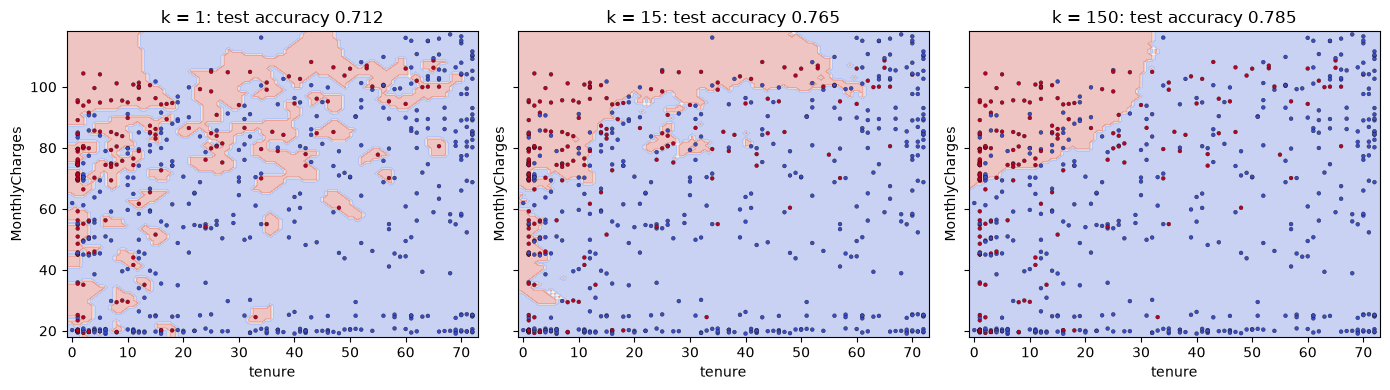

In [22]:
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.neighbors import KNeighborsClassifier

two = ["tenure", "MonthlyCharges"]
sample = X_train[two].sample(600, random_state=0)
y_sample = y_train.loc[sample.index]
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, k in zip(axes, [1, 15, 150]):
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)).fit(sample, y_sample)
    DecisionBoundaryDisplay.from_estimator(model, sample, response_method="predict", cmap="coolwarm",
                                           alpha=0.3, ax=ax)
    ax.scatter(sample["tenure"], sample["MonthlyCharges"], c=y_sample, cmap="coolwarm", s=8, edgecolor="k", lw=0.2)
    ax.set_title(f"k = {k}: test accuracy {model.score(X_test[two], y_test):.3f}")
plt.tight_layout()
plt.show()

Red areas are predicted "churns", blue areas "stays". With *k* = 1 the churn region is a patchwork of small islands around individual customers; with *k* = 150 it is one smooth region of customers with a short tenure and high charges, which matches what the business already suspected.

### Choosing *k* by cross-validation

**Predict before running.** How will the training score and the validation score change as *k* grows from 1 to 1,500?

`GridSearchCV(pipeline, {"kneighborsclassifier__n_neighbors": [...]})` tries each *k* in every fold; the parameter name is the step name, two underscores, then the parameter. `return_train_score=True` also keeps the training score. We score with `"f1_macro"`, which rewards finding churners as well as stayers (defined in the macro-F1 section).

In [23]:
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier

knn_search = GridSearchCV(make_pipeline(pre, KNeighborsClassifier()),
                          {"kneighborsclassifier__n_neighbors": [1, 5, 15, 50, 150, 500, 1500]},
                          cv=cv, scoring="f1_macro", return_train_score=True).fit(X_train, y_train)
res = pd.DataFrame(knn_search.cv_results_)
print(res[["param_kneighborsclassifier__n_neighbors", "mean_train_score", "mean_test_score"]]
      .round(3).to_string(index=False))
print("best:", knn_search.best_params_)

 param_kneighborsclassifier__n_neighbors  mean_train_score  mean_test_score
                                       1             0.997            0.637
                                       5             0.790            0.701
                                      15             0.757            0.721
                                      50             0.741            0.732
                                     150             0.729            0.727
                                     500             0.725            0.722
                                    1500             0.529            0.526
best: {'kneighborsclassifier__n_neighbors': 50}


With *k* = 1 the training score is almost perfect and the validation score is the worst of the small *k*: overfitting. With 1,500 neighbours the model is close to "nobody churns" and both scores collapse: underfitting. The best *k* lies in between. A plot of both curves against *k* (on a log scale) makes the pattern visible:

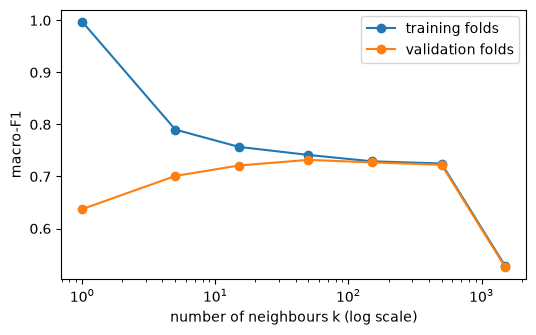

In [24]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ks = res["param_kneighborsclassifier__n_neighbors"].astype(int)
ax.plot(ks, res["mean_train_score"], marker="o", label="training folds")
ax.plot(ks, res["mean_test_score"], marker="o", label="validation folds")
ax.set(xscale="log", xlabel="number of neighbours k (log scale)", ylabel="macro-F1")
ax.legend()
plt.show()

### Uniform and distance weights

*Adapted from [Nearest Neighbors Classification](https://scikit-learn.org/1.9/auto_examples/neighbors/plot_classification.html) (scikit-learn developers, BSD-3-Clause).*

By default every neighbour has the same vote (`weights="uniform"`). With `weights="distance"` each neighbour's vote is weighted by the inverse of its distance, so close neighbours count more. `pipeline.set_params(kneighborsclassifier__weights=...)` changes the setting of a step inside a pipeline.

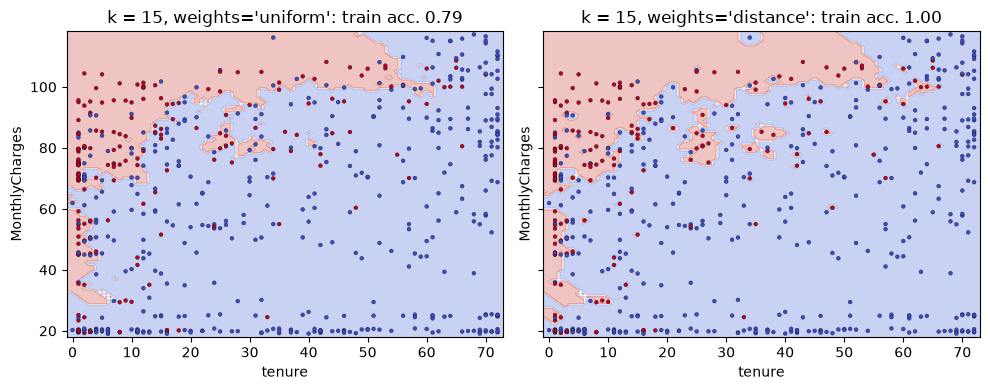

In [25]:
model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15))
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, w in zip(axes, ["uniform", "distance"]):
    model.set_params(kneighborsclassifier__weights=w).fit(sample, y_sample)
    DecisionBoundaryDisplay.from_estimator(model, sample, response_method="predict", cmap="coolwarm",
                                           alpha=0.3, ax=ax)
    ax.scatter(sample["tenure"], sample["MonthlyCharges"], c=y_sample, cmap="coolwarm", s=8, edgecolor="k", lw=0.2)
    ax.set_title(f"k = 15, weights={w!r}: train acc. {model.score(sample, y_sample):.2f}")
plt.tight_layout()
plt.show()

With distance weights every training customer is again its own (infinitely close) neighbour, so the training accuracy jumps to 1 and the boundary becomes more jagged: distance weighting makes k-NN more flexible. Whether that helps is, once more, a question for cross-validation; `weights` can go into the `GridSearchCV` grid next to `n_neighbors`.

### Limits of k-NN

k-NN must compare each new case with all stored training cases, so prediction gets slow on large data, and with many irrelevant columns all points look equally far apart (the "curse of dimensionality"). Logistic regression or trees (Session 10) are usually preferred in production; k-NN remains the clearest picture of flexibility against stability. Nearest-neighbour search itself returns in Sessions 14 and 15, where documents are retrieved by their distance to a query.

> 📖 **Read more:** [extras/04-knn-decision-boundary.ipynb](extras/04-knn-decision-boundary.ipynb) (scikit-learn gallery): k-NN decision boundaries on the iris data with uniform and distance weights.

## Confusion matrix, accuracy, precision, recall and F1

A classifier can be wrong in two ways. This section counts both kinds of error and turns the counts into the standard metrics.

### The confusion matrix

A **confusion matrix** counts the four possible outcomes of a yes/no prediction. With churn as the positive class:

| | predicted: stays | predicted: churns |
|---|---|---|
| **truly stays** | true negative (TN) | false positive (FP): a loyal customer wrongly flagged |
| **truly churns** | false negative (FN): a churner missed | true positive (TP) |

`confusion_matrix(y_true, y_pred)` puts the **truth in rows** and the **prediction in columns**, in sorted class order (0, then 1). `.ravel()` unpacks the four counts.

In [26]:
from sklearn.metrics import confusion_matrix

pred = logreg.predict(X_test)
print(confusion_matrix(y_test, pred))
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
print(f"TN {tn}  FP {fp}  FN {fn}  TP {tp}")

[[1146  148]
 [ 219  248]]
TN 1146  FP 148  FN 219  TP 248


### Accuracy, precision, recall and F1

From these four counts:

- **accuracy** = (TP + TN) / all: the share of correct predictions;
- **precision** = TP / (TP + FP): of the customers we flag, how many really churn? *How much of our effort is well spent?*
- **recall** = TP / (TP + FN): of the customers who churn, how many do we flag? *How many cases do we find?*
- **F1** = 2 · precision · recall / (precision + recall), the harmonic mean. It is high only when both are high: a model with precision 1.0 and recall 0.01 has F1 of about 0.02.

A fishing net is a good picture: recall is the share of the fish in the lake that you catch, precision the share of your catch that is fish rather than old boots. A bigger net catches more fish and more boots.

**Predict before running.** Compute precision and recall from the four counts above on paper, then check with the next cell. `precision_score`, `recall_score` and `f1_score` take the true and the predicted classes.

In [27]:
from sklearn.metrics import f1_score, precision_score

print("by hand:  precision", round(tp / (tp + fp), 3), " recall", round(tp / (tp + fn), 3))
print("sklearn:  precision", round(precision_score(y_test, pred), 3),
      " recall", round(recall_score(y_test, pred), 3), " F1", round(f1_score(y_test, pred), 3))

by hand:  precision 0.626  recall 0.531
sklearn:  precision 0.626  recall 0.531  F1 0.575


The model is about 79 % accurate, yet it misses almost half of the churners: the false negatives in the bottom-left cell. Precision and recall answer different business questions. A retention team with a small budget wants high precision (no wasted offers); a hospital screening for a disease wants high recall (no missed patients). F1 is a compromise when both matter and nobody has put a price on the errors yet; Block 2 replaces it with real costs.

### Drawing the matrix and the classification report

`ConfusionMatrixDisplay.from_predictions` draws the matrix with labelled axes. `classification_report` prints precision, recall and F1 for each class, plus their averages (next section).

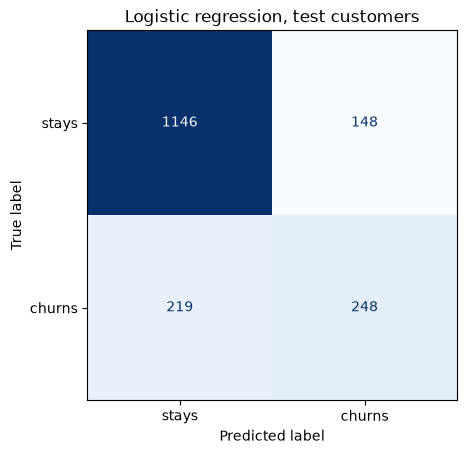

              precision    recall  f1-score   support

       stays      0.840     0.886     0.862      1294
      churns      0.626     0.531     0.575       467

    accuracy                          0.792      1761
   macro avg      0.733     0.708     0.718      1761
weighted avg      0.783     0.792     0.786      1761



In [28]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["stays", "churns"],
                                        cmap="Blues", colorbar=False)
plt.title("Logistic regression, test customers")
plt.show()
print(classification_report(y_test, pred, target_names=["stays", "churns"], digits=3))

> **Note.** Some textbooks put the prediction in rows. Always label the axes, and say which class is positive.

### Normalised confusion matrices

*Adapted from [Evaluate the performance of a classifier with Confusion Matrix](https://scikit-learn.org/1.9/auto_examples/model_selection/plot_confusion_matrix.html) (scikit-learn developers, BSD-3-Clause).*

Raw counts are hard to compare when the classes differ in size. `normalize="true"` divides each row by its total, so the diagonal shows the recall of each class; `normalize="pred"` divides each column, so the diagonal shows the precision of each predicted class. With class imbalance, the row-normalised matrix shows at a glance which class is being misclassified.

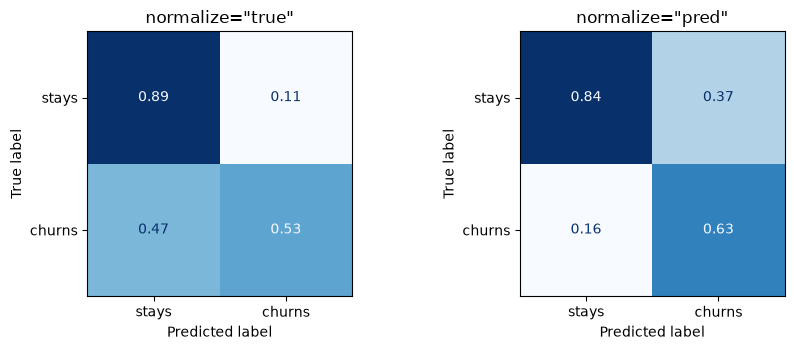

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, norm in zip(axes, ["true", "pred"]):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, normalize=norm, display_labels=["stays", "churns"],
                                            cmap="Blues", colorbar=False, values_format=".2f", ax=ax)
    ax.set_title(f'normalize="{norm}"')
plt.tight_layout()
plt.show()

### Sensitivity, specificity and balanced accuracy

*Adapted from [Classification](https://inria.github.io/scikit-learn-mooc/python_scripts/metrics_classification.html) (INRIA scikit-learn MOOC, CC BY 4.0).*

Medicine uses another pair of names. **Sensitivity** is recall: TP / (TP + FN). **Specificity** is the recall of the negative class: TN / (TN + FP), the share of healthy people (loyal customers) correctly left alone. **Balanced accuracy** is the mean of the recalls of all classes; with two classes it is (sensitivity + specificity) / 2. On balanced data it equals accuracy; on imbalanced data it does not reward ignoring the small class, because "nobody churns" gets 1.0 on one class and 0 on the other, so 0.5.

In [30]:
from sklearn.metrics import balanced_accuracy_score

print("sensitivity", round(tp / (tp + fn), 3), "| specificity", round(tn / (tn + fp), 3))
for name, p in [("nobody churns", dummy.predict(X_test)), ("logistic regression", pred)]:
    print(f"{name:20s} accuracy {accuracy_score(y_test, p):.3f}   balanced accuracy {balanced_accuracy_score(y_test, p):.3f}")

sensitivity 0.531 | specificity 0.886
nobody churns        accuracy 0.735   balanced accuracy 0.500
logistic regression  accuracy 0.792   balanced accuracy 0.708


### String labels, `pos_label` and `zero_division`

*Adapted from [Classification](https://inria.github.io/scikit-learn-mooc/python_scripts/metrics_classification.html) (INRIA scikit-learn MOOC, CC BY 4.0).*

Precision, recall and F1 depend on which class is positive. With 0/1 labels, 1 is positive by default. Many real targets are strings ("Yes"/"No", "donated"/"not donated"); then you must say which one is positive with `pos_label`, or scikit-learn raises an error. A second trap: a model that never predicts the positive class has no flagged customers, so its precision is 0 / 0. `zero_division=0` reports it as 0 instead of warning.

In [31]:
truth_str = telco.loc[X_test.index, "Churn"]                 # "Yes" / "No"
pred_str = np.where(pred == 1, "Yes", "No")
try:
    precision_score(truth_str, pred_str)
except ValueError as err:
    print("without pos_label:", str(err)[:70], "...")
print("pos_label='Yes':", round(precision_score(truth_str, pred_str, pos_label="Yes"), 3))
print("never flags anybody:", precision_score(y_test, dummy.predict(X_test), zero_division=0))

without pos_label: pos_label=1 is not a valid label. It should be one of ['No' 'Yes'] ...
pos_label='Yes': 0.626
never flags anybody: 0.0


### Predicted classes come from probabilities

*Adapted from [Classification](https://inria.github.io/scikit-learn-mooc/python_scripts/metrics_classification.html) (INRIA scikit-learn MOOC, CC BY 4.0) and [Evaluate the performance of a classifier with Confusion Matrix](https://scikit-learn.org/1.9/auto_examples/model_selection/plot_confusion_matrix.html) (scikit-learn developers, BSD-3-Clause).*

Every number in this section was computed from `predict`, which, for two classes, flags a customer when the predicted probability of churn is at least 0.5. Equivalently, it picks the class with the highest probability. We check that on the test set:

In [32]:
proba = logreg.predict_proba(X_test)
print("predict == argmax of predict_proba:", np.array_equal(logreg.classes_[proba.argmax(axis=1)], pred))
print("predict == (p >= 0.5):", np.array_equal((proba[:, 1] >= 0.5).astype(int), pred))

predict == argmax of predict_proba: True
predict == (p >= 0.5): True


The threshold 0.5 is a choice, not a law. `confusion_matrix_at_thresholds(y_true, scores)` returns the four counts for every possible threshold. The plot shows how lowering the threshold trades false negatives for false positives; Block 2 chooses the threshold from what each error costs.

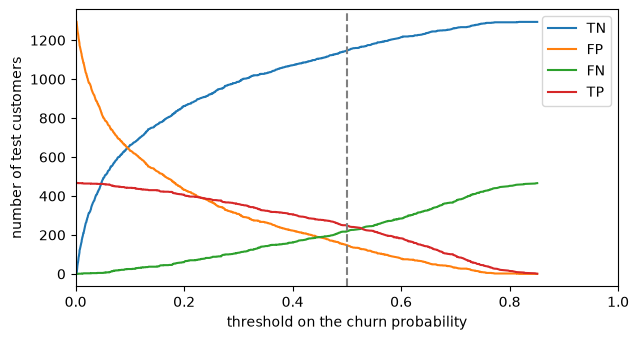

In [33]:
from sklearn.metrics import confusion_matrix_at_thresholds

tns, fps, fns, tps, thresholds = confusion_matrix_at_thresholds(y_test, proba[:, 1])
fig, ax = plt.subplots(figsize=(7, 3.6))
for counts, label in [(tns, "TN"), (fps, "FP"), (fns, "FN"), (tps, "TP")]:
    ax.plot(thresholds, counts, label=label)
ax.axvline(0.5, ls="--", color="grey")
ax.set(xlabel="threshold on the churn probability", ylabel="number of test customers", xlim=(0, 1))
ax.legend()
plt.show()

> 📖 **Read more:** [extras/05-confusion-matrix.ipynb](extras/05-confusion-matrix.ipynb) (scikit-learn gallery): normalised confusion matrices on the iris data and counts at every threshold. [extras/06-classification-metrics.ipynb](extras/06-classification-metrics.ipynb) (INRIA scikit-learn MOOC): accuracy, balanced accuracy, precision and recall on the blood transfusion data, with a dummy baseline.

## Macro-F1 for several classes

With more than two classes, precision, recall and F1 are computed **per class**: each class in turn plays "positive" against all others (one-vs-rest).

### Macro, weighted and micro averages

The per-class scores are then averaged:

- **macro-F1**: the plain mean of the per-class F1 scores. Every class counts equally, however rare;
- **weighted F1**: the mean weighted by class size, dominated by the big classes;
- **micro-F1**: pools all decisions before computing F1; for single-label problems it equals accuracy.

Macro-F1 also helps with two classes: it averages the F1 of "churns" and of "stays", so a model that never flags anybody cannot hide behind the big class. Session 13 meets a customs task with almost a thousand classes, where accuracy and macro-F1 tell very different stories.

### Macro-F1 on a toy example and on the churn models

A small example first: a shop predicts which contract ten new customers will choose (M = month-to-month, 1Y, 2Y). `f1_score(..., average=None)` gives one F1 per class; `average="macro"` their mean.

**Predict before running.** Two predictions are wrong, both of a rare class. Will macro-F1 be above or below the accuracy of 0.8?

In [34]:
y_true = ["M"] * 6 + ["1Y", "1Y", "2Y", "2Y"]
y_pred = ["M"] * 6 + ["M", "1Y", "M", "2Y"]
print("per class:", f1_score(y_true, y_pred, average=None, labels=["M", "1Y", "2Y"]).round(2))
print("macro-F1:", round(f1_score(y_true, y_pred, average="macro"), 2),
      "| accuracy:", accuracy_score(y_true, y_pred))

per class: [0.86 0.67 0.67]
macro-F1: 0.73 | accuracy: 0.8


The same comparison for the churn baseline and the logistic regression on the test customers:

In [35]:
for name, p in [("nobody churns", dummy.predict(X_test)), ("logistic regression", pred)]:
    print(f"{name:20s} accuracy {accuracy_score(y_test, p):.3f}   macro-F1 {f1_score(y_test, p, average='macro'):.3f}")

nobody churns        accuracy 0.735   macro-F1 0.424
logistic regression  accuracy 0.792   macro-F1 0.718


The gap between the two models is about 6 points in accuracy but about 30 points in macro-F1: macro-F1 makes the uselessness of the baseline visible.

> **Note.** `f1_score` on more than two classes needs `average=`. Always say which average you report.

### A three-class task on the Telco data

A real multiclass example: the sales team wants to predict which **contract** a customer holds from everything else we know (services, charges, payment method, tenure). Three classes of unequal size. We reuse the preparation of the pipeline section with `Contract` removed from the features; `LogisticRegression` handles several classes directly.

In [36]:
Xc = X.drop(columns="Contract")
yc = X["Contract"]
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size=0.25, stratify=yc, random_state=0)
pre_c = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore"), [c for c in categorical if c != "Contract"]),
])
contract_model = make_pipeline(pre_c, LogisticRegression(max_iter=2000)).fit(Xc_train, yc_train)
yc_pred = contract_model.predict(Xc_test)
print(yc_train.value_counts(normalize=True).round(3).to_dict())

{'Month-to-month': 0.55, 'Two year': 0.241, 'One year': 0.209}


`classification_report` lists precision, recall and F1 per class, then the **macro avg** and **weighted avg** rows. `average="micro"` can be computed separately and equals accuracy.

In [37]:
print(classification_report(yc_test, yc_pred, digits=3))
print("micro-F1", round(f1_score(yc_test, yc_pred, average="micro"), 3),
      "= accuracy", round(accuracy_score(yc_test, yc_pred), 3))

                precision    recall  f1-score   support

Month-to-month      0.815     0.926     0.867       969
      One year      0.512     0.283     0.364       368
      Two year      0.714     0.771     0.741       424

      accuracy                          0.754      1761
     macro avg      0.681     0.660     0.658      1761
  weighted avg      0.728     0.754     0.732      1761

micro-F1 0.754 = accuracy 0.754


The month-to-month class is found well; the middle class "One year" is the hardest, because it lies between the two others in tenure and charges. Its low F1 pulls macro-F1 below the weighted average, which is dominated by the big month-to-month class. A row-normalised confusion matrix shows where the errors go:

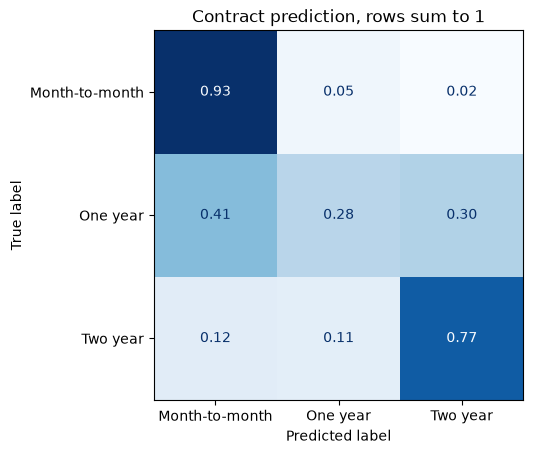

In [38]:
ConfusionMatrixDisplay.from_predictions(yc_test, yc_pred, normalize="true", values_format=".2f",
                                        cmap="Blues", colorbar=False)
plt.title("Contract prediction, rows sum to 1")
plt.show()

Only about a quarter of the "One year" customers are recognised; the others are split between month-to-month and two-year predictions. The middle class is confused with both of its neighbours, while the two outer classes are rarely confused with each other. Block 2 returns to this model for multiclass ROC curves.

## Worked example · Which churn model should the retention team use?

We now compare the four candidates fairly: the majority baseline, the hand-made rule, k-NN with the *k* chosen above, and the logistic regression. All numbers come from 5-fold cross-validation on the **training** customers; the test set stays locked.

`cross_val_predict(model, X, y, cv=cv)` returns an **out-of-fold** prediction for every training customer: each one is predicted by a model that did not see it. The rule learns nothing, so we apply it directly. A small helper `summary` collects the five metrics; `zero_division=0` reports the undefined precision of a model that never flags anybody as 0.

In [39]:
from sklearn.model_selection import cross_val_predict


def summary(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred), "F1": f1_score(y_true, y_pred),
            "macro-F1": f1_score(y_true, y_pred, average="macro")}


rule_train = ((X_train["Contract"] == "Month-to-month") & (X_train["tenure"] < 12)).astype(int)
k = knn_search.best_params_["kneighborsclassifier__n_neighbors"]
rows = {"nobody churns": summary(y_train, np.zeros(len(y_train), dtype=int)),
        "rule": summary(y_train, rule_train),
        f"{k}-NN": summary(y_train, cross_val_predict(knn_search.best_estimator_, X_train, y_train, cv=cv)),
        "logistic regression": summary(y_train, cross_val_predict(logreg, X_train, y_train, cv=cv))}
comparison = pd.DataFrame(rows).T.round(3)
comparison

,accuracy,precision,recall,F1,macro-F1
nobody churns,0.735,0.000,0.000,0.000,0.423
rule,0.741,0.513,0.522,0.517,0.670
50-NN,0.794,0.617,0.589,0.603,0.732
logistic regression,0.806,0.661,0.554,0.603,0.737


Reading the table:

- "Nobody churns" has a respectable accuracy and zero recall. It is the floor.
- The rule finds about half of the churners, but about every second flagged customer is a false alarm.
- k-NN and logistic regression beat the rule on every metric. They have the same F1: logistic regression is ahead in accuracy, precision and macro-F1, k-NN finds a few more churners. Logistic regression is also easier to explain (Session 6), so it becomes the churn model of Block 2.

Only now do we look at the test set, once, for the chosen model and the rule. `plt.subplots(1, 2)` puts the two matrices side by side.

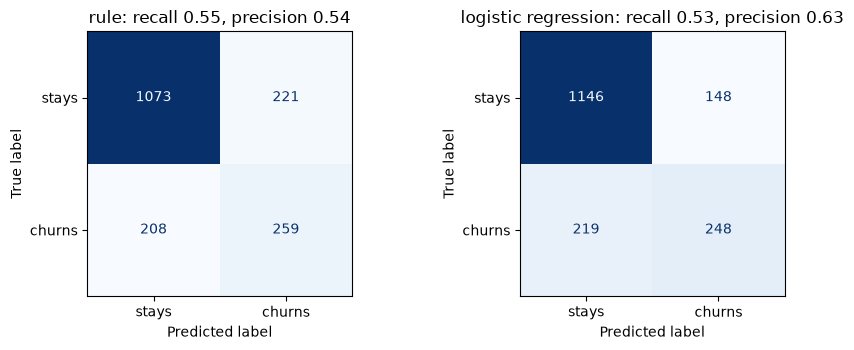

In [40]:
rule_test = ((X_test["Contract"] == "Month-to-month") & (X_test["tenure"] < 12)).astype(int)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, (name, p) in zip(axes, [("rule", rule_test), ("logistic regression", pred)]):
    ConfusionMatrixDisplay.from_predictions(y_test, p, display_labels=["stays", "churns"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"{name}: recall {recall_score(y_test, p):.2f}, precision {precision_score(y_test, p):.2f}")
plt.tight_layout()
plt.show()

Which metric fits depends on the question. *How many of the people we call will really leave?* is precision. *How many leavers do we reach?* is recall. *Is the model better than doing nothing, for both groups?* is macro-F1 against the baseline. None of them yet says *how many* customers to call; that needs the predicted probabilities and the cost of each error, which is Block 2.

## Check your understanding

1. For each column, choose one-hot or ordinal encoding and justify: `PaymentMethod`, `Contract`, `InternetService`, a satisfaction score from 1 to 5.
2. What happens to the `StandardScaler` inside a pipeline when you call `cross_val_score(pipeline, X, y, cv=5)`?
3. A 1-NN model has a training accuracy of 99.7 %. Why does that say nothing about its quality?
4. A model has TP = 50, FP = 30, FN = 20, TN = 900. Compute precision, recall and accuracy. Why is the accuracy misleading?
5. Why does macro-F1 punish a model that never predicts the rare class, while accuracy hardly notices?

## Exercises (30 min)

Work in pairs. The lecturer picks which exercises to set; there are more than fit into 30 minutes. Answer *Paper* and *Predict* tasks in the markdown cell below the task before running any code, *Code* tasks in the empty code cells. The variables of this notebook (`X_train`, `y_train`, `cv`, `numeric`, `categorical`, `pre`, `summary`, `comparison`) are available.

### 1.1 · k-NN on graph paper

*Paper · 10 min*

> Six training points in two features: class A at (1, 1), (2, 1) and (1, 2); class B at (4, 4), (5, 4) and (3, 3). Classify the new point (2.5, 2.5) with k = 1 and with k = 3 (Euclidean distance).
>
> What is the training accuracy of 1-NN, and why is that suspicious?

*Source:* [k-nearest neighbors algorithm, Wikipedia](https://en.wikipedia.org/wiki/K-nearest_neighbors_algorithm); the six points are an original example for this course

*Your answer:*

### 1.2 · Fill the confusion matrix from a story

*Paper · 10 min*

> 100 customers, 20 churn; the model flags 25, of whom 15 churn. Fill the confusion matrix and compute precision, recall and F1.

*Source:* original exercise for this course; background: [Precision and recall, Wikipedia](https://en.wikipedia.org/wiki/Precision_and_recall)

*Your answer:*

### 1.3 · The 99 % accurate medical test

*Paper · 10 min*

> Prevalence 1 %, sensitivity and specificity 99 %. You test positive: how likely are you ill?

*Source:* [Base rate fallacy, Wikipedia](https://en.wikipedia.org/wiki/Base_rate_fallacy)

*Your answer:*

### 1.4 · Does k-NN need the scaler?

*Code · 20 min*

> Build two pipelines with a `ColumnTransformer` (one-hot encoding of the categorical columns) and `KNeighborsClassifier(n_neighbors=50)`: one that scales the numeric columns with `StandardScaler` and one that passes them through unscaled. Encode `Contract` with an `OrdinalEncoder` in the order month-to-month, one year, two year in both.
>
> Compare the two with 5-fold cross-validation (`cv`) on the training data: accuracy, recall of churners and macro-F1. Which numeric column dominates the distances without scaling, and why?

*Source:* original exercise for this course; background: [scikit-learn: Importance of feature scaling](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_scaling_importance.html)

### 1.5 · Which metric for which question?

*Pairs · 5 min*

> Three teams ask about the churn model. For each, name the metric that fits and the model from the worked example you would give them.
>
> 1. *Marketing* can make 300 retention calls per quarter and wants as many of the called customers as possible to be real churners.
> 2. *Customer care* wants to miss as few churners as possible and accepts many unnecessary calls.
> 3. *Management* wants to know whether the model is better than the current rule for stayers and churners alike.

*Source:* original exercise for this course

*Your answer:*

### 1.6 · Beat the rule

*Code · 15 min · Stretch*

> Write a hand-made churn rule of your own (for example "electronic check and no tech support", or a different tenure limit). Evaluate it on the training customers with `summary(y_train, ...)` and add it to `comparison`. Does any rule of yours beat the logistic regression on recall? On macro-F1?

*Source:* original exercise for this course

## Debrief (15 min)

- **Compare** two confusion matrices filled from the story in 1.2. A common mistake swaps the 5 false negatives and the 10 false positives; ask "who was flagged?" and "who left?" to place them.
- **1.3:** let a pair that answered "99 %" explain their reasoning, then count 10,000 people through the test. The same base-rate effect is why precision falls when churners are rare.
- **1.4:** ask which column dominated the distances without scaling and what the nearest neighbours of a customer then have in common.
- **1.5:** check that "300 calls" was read as a precision question and "miss as few as possible" as recall.
- **Bridge to Block 2.** Every number today was computed at the default threshold of 0.5. The model gives probabilities: next we evaluate them over all thresholds, choose the threshold from the money at stake, and deal with churners being the minority.

## Further reading

- James, G., Witten, D., Hastie, T., Tibshirani, R. & Taylor, J. (2023). *An Introduction to Statistical Learning with Applications in Python*, Sections 2.2 (k-nearest neighbours) and 4.4 (classification). Springer. https://www.statlearning.com/
- INRIA. *scikit-learn MOOC*, Module 1 ("Preprocessing for numerical features", "Encoding of categorical variables", "Using numerical and categorical variables together") and "Classification" metrics. CC BY 4.0. https://inria.github.io/scikit-learn-mooc/
- scikit-learn developers. *Pipelines and composite estimators*, *Nearest neighbors* and *Metrics and scoring*. https://scikit-learn.org/stable/modules/compose.html · https://scikit-learn.org/stable/modules/neighbors.html · https://scikit-learn.org/stable/modules/model_evaluation.html
- Google for Developers. *Machine Learning Crash Course: Classification*. https://developers.google.com/machine-learning/crash-course/classification
- IBM (2019). *Telco customer churn sample data*. https://github.com/IBM/telco-customer-churn-on-icp4d
- Extras of this block: [01](extras/01-categorical-encoding.ipynb), [02](extras/02-scaling-in-pipelines.ipynb), [03](extras/03-column-transformer.ipynb), [04](extras/04-knn-decision-boundary.ipynb), [05](extras/05-confusion-matrix.ipynb), [06](extras/06-classification-metrics.ipynb). Provenance and licences: [extras/README.md](extras/README.md).